# Project 2 — Credit Card Fraud: an Anomaly Detector to Prioritise Fraud Investigations

**Course:** DSC8307 Data Mining, Modeling and Analytics — Assignment 2

**Student name:** NAMUYOMBA NAKACHWA EMILLY
**Registration number:** S25M19/047
**Access number:** B35963


## Executive summary

**Goal.** Rank card transactions from most to least suspicious so that investigators check the likeliest frauds first. The fraud labels are **withheld**: they are used only to evaluate the rankings.

**Main results** (evaluation period: the last 30% of the two days, 85,117 transactions, 107 frauds)
- **Preparation.** 1,081 duplicate rows were removed. Amount was log-transformed. `Time` was not used as a feature. The features were standardised on the earlier development period.
- **Statistical baseline (Mahalanobis distance):** PR-AUC **0.036**, ROC-AUC **0.946**. That is already about 17 times better than random ranking (0.002) in PR-AUC.
- **Cluster-based detector (distance to the nearest of 10 k-means centroids):** PR-AUC **0.045**, ROC-AUC **0.951**. Investigating its top 1,000 transactions would catch **57% of frauds** (61 of 107).
- **Classification-based detector (One-Class SVM trained on unlabelled development data):** PR-AUC **0.040**, ROC-AUC **0.935**. Its top 1,000 catch 51% of frauds but **64% of the fraudulent euros**.
- **The two approaches are statistically tied** (PR-AUC difference −0.005, 95% CI [−0.010, 0.001]). Both clearly beat random ranking and modestly beat the statistical baseline. Sensitivity analysis shows both depend on settings chosen without labels (k, training sample).
- **Why unusual ≠ fraud.** The **100 most unusual transactions contain no frauds at all** for every detector. They are mostly large, rare but legitimate payments (median €446, against €7 for frauds). Even an excellent detector would mostly flag genuine transactions, because fraud is so rare (the base-rate effect).
- **Reference.** A supervised model trained on past labels reaches PR-AUC 0.70, showing how much value confirmed fraud labels add on top of "unusualness".


## Problem formulation

**Business problem.** A card issuer cannot manually check every transaction. It needs a list of **transactions ranked from most to least suspicious**, so investigators with limited time check the most suspicious first. The detector is judged by **how many real frauds appear near the top of that list**.

**Analytical formulation.** This is **anomaly (outlier) detection**: "the identification of rare items, events, or observations that raise suspicions by differing significantly from the majority of the data". It is **unsupervised**: each detector gives every transaction an **anomaly score**, and higher means more unusual.

**What kind of anomalies? ( "Types of anomalies")**

| Type | In this problem |
|---|---|
| **Global** anomaly: unusual compared with all data | What our detectors look for, e.g. an extreme combination of feature values |
| **Contextual** anomaly: unusual only in context | Possible (e.g. a purchase normal by day but odd at 3 a.m., or odd *for this cardholder*), but the data has **no cardholder ID**, so context is limited |
| **Collective** anomaly: a group of transactions unusual together | Possible (e.g. several rapid small test charges), but transactions cannot be linked to cards, so this cannot be detected here |

**How success is measured (only at the evaluation stage, using the withheld labels)**
- **PR-AUC (average precision):** the main measure for a ranking where positives are very rare (0.17%). A random ranking scores about 0.0017.
- **ROC-AUC:** the probability that a fraud is ranked above a genuine transaction (random = 0.5).
- **Precision@k and recall@k:** of the top *k* transactions investigated (k = 100, 500, 1,000), what share are frauds, and what share of all frauds are caught? These match an investigation team's **daily capacity**.
- **Amount recall:** the share of fraudulent **euros** caught in the top k.

In [43]:

## Set-up and reproducibility
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from pandas.api.types import is_numeric_dtype
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.svm import OneClassSVM
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0 | scipy 1.17.1


In [44]:
## Data selection: loading the data
credit=pd.read_csv("creditcard.csv")
V_COLS = [f"V{i}" for i in range(1, 29)]     # names of the 28 anonymised PCA features: V1 ... V28
credit                                  # the later cells in this notebook use the name `cc`
print("Number of transactions = %d, number of columns = %d" % credit.shape)

Number of transactions = 284807, number of columns = 31


In [45]:
credit

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,"172,786.0000",-11.8811,10.0718,-9.8348,-2.0667,-5.3645,-2.6068,-4.9182,7.3053,1.9144,...,0.2135,0.1119,1.0145,-0.5093,1.4368,0.2500,0.9437,0.8237,0.7700,0
284803,"172,787.0000",-0.7328,-0.0551,2.0350,-0.7386,0.8682,1.0584,0.0243,0.2949,0.5848,...,0.2142,0.9244,0.0125,-1.0162,-0.6066,-0.3953,0.0685,-0.0535,24.7900,0
284804,"172,788.0000",1.9196,-0.3013,-3.2496,-0.5578,2.6305,3.0313,-0.2968,0.7084,0.4325,...,0.2320,0.5782,-0.0375,0.6401,0.2657,-0.0874,0.0045,-0.0266,67.8800,0
284805,"172,788.0000",-0.2404,0.5305,0.7025,0.6898,-0.3780,0.6237,-0.6862,0.6791,0.3921,...,0.2652,0.8000,-0.1633,0.1232,-0.5692,0.5467,0.1088,0.1045,10.0000,0


In [46]:
credit.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


| Column | Meaning (from the README) |
|---|---|
| `Time` | Seconds since the first transaction in the data (two days) |
| `V1`–`V28` | **Principal components** of the original (confidential) transaction features: anonymised, so their meaning is unknown |
| `Amount` | Transaction amount in euros |
| `Class` | 1 = fraud, 0 = genuine. **Withheld**: used only for evaluation |

In [47]:

## Data exploration (without using the labels)
### Summary statistics
desc = credit[["Time", "Amount"] + V_COLS].describe().T
desc["skew"] = credit[["Time", "Amount"] + V_COLS].skew()
desc[["mean", "std", "min", "50%", "max", "skew"]]

,mean,std,min,50%,max,skew
Time,"94,813.8596","47,488.1460",0.0000,"84,692.0000","172,792.0000",-0.0356
Amount,88.3496,250.1201,0.0000,22.0000,"25,691.1600",16.9777
V1,0.0000,1.9587,-56.4075,0.0181,2.4549,-3.2807
V2,0.0000,1.6513,-72.7157,0.0655,22.0577,-4.6249
V3,-0.0000,1.5163,-48.3256,0.1798,9.3826,-2.2402
V4,0.0000,1.4159,-5.6832,-0.0198,16.8753,0.6763
V5,0.0000,1.3802,-113.7433,-0.0543,34.8017,-2.4259
V6,0.0000,1.3323,-26.1605,-0.2742,73.3016,1.8266
V7,-0.0000,1.2371,-43.5572,0.0401,120.5895,2.5539
V8,0.0000,1.1944,-73.2167,0.0224,20.0072,-8.5219


**What we learn**
- **V1–V28 all have mean ≈ 0**, and their standard deviations **decrease from V1 (about 1.96) to V28 (about 0.33)**. That is exactly what principal components look like: centred, uncorrelated, and ordered by variance. They are already on comparable scales.
- Several V-features have **extreme tails**, for example a minimum of −113.7 for V5, a maximum of 120.6 for V7, and skewness up to 11 (V28). These hint at rare, unusual transactions.
- **Amount** ranges from €0 to **€25,691**, with a median of only **€22** and a mean of €88. It is very right-skewed (skewness about 17).
- **Time** runs from 0 to 172,792 seconds, i.e. **48 hours**.

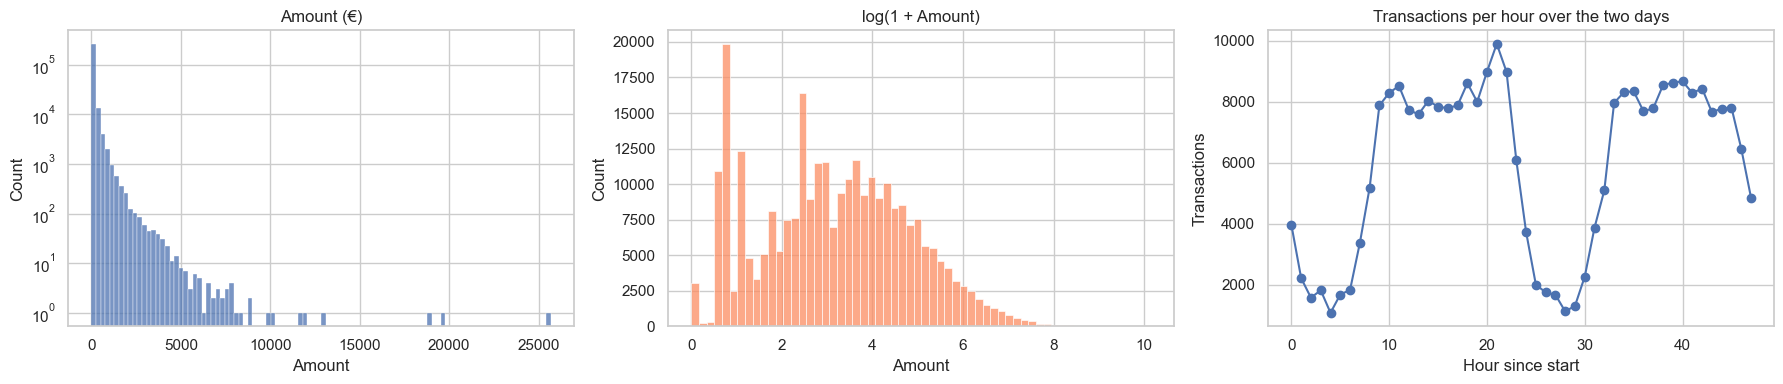

Transactions with Amount = 0: 1825


In [48]:
### Amount and Time
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(credit["Amount"], bins=100, ax=axes[0]); axes[0].set(title="Amount (€)", yscale="log")
sns.histplot(np.log1p(credit["Amount"]), bins=60, ax=axes[1], color="#fc8d62"); axes[1].set(title="log(1 + Amount)")
hours = (credit["Time"] // 3600).astype(int)
hours.value_counts().sort_index().plot(ax=axes[2], marker="o"); axes[2].set(title="Transactions per hour over the two days", xlabel="Hour since start", ylabel="Transactions")
plt.tight_layout() 
plt.show()
print("Transactions with Amount = 0: %d" % (credit["Amount"] == 0).sum())

**What we learn**
- **Amount** spans several orders of magnitude, so `log(1 + Amount)` gives a much more even distribution. **1,825** transactions have **Amount = 0** (possibly card verification checks).
- **Time shows a clear daily cycle:** activity drops sharply during two night periods (around hours 2–5 and 26–29 after the start) and is high during the day. Raw `Time` is just a clock since the start of the file, so a large value doesn't make a transaction suspicious in itself. Time of day may provide *context*, though.


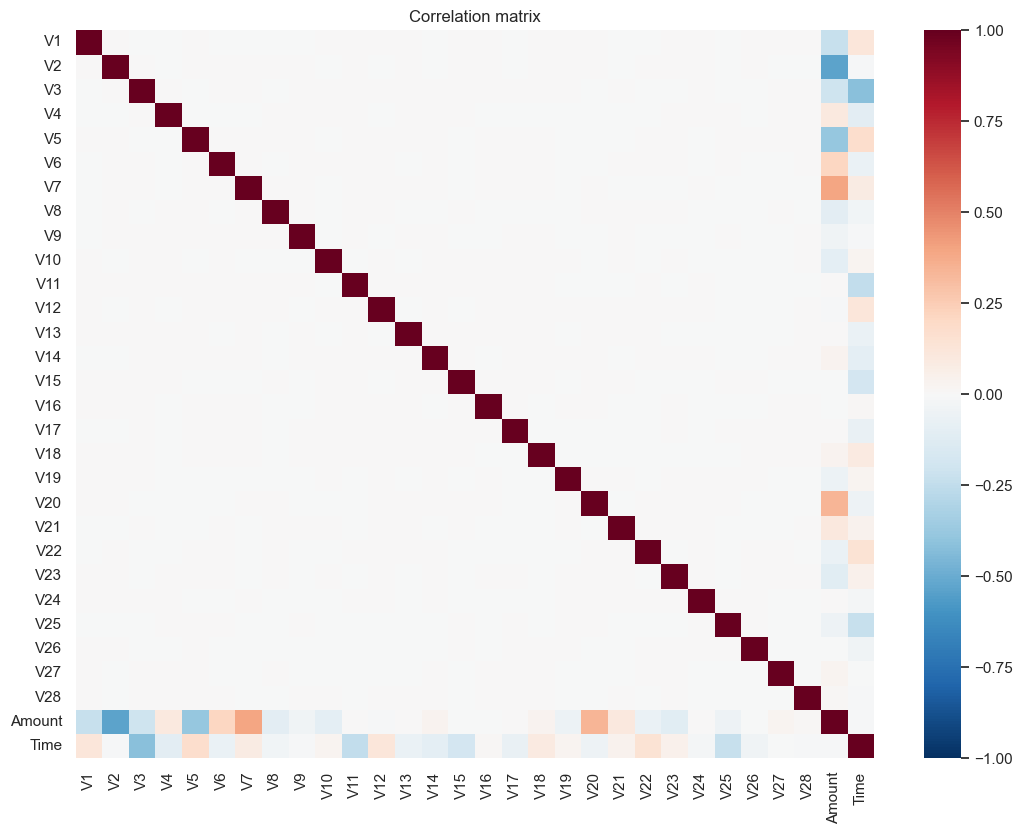

In [49]:

### Correlation between features
plt.figure(figsize=(11, 8.5))
sns.heatmap(credit[V_COLS + ["Amount", "Time"]].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

**What we learn.** 
-   The V-features are **uncorrelated with each other** (the PCA property), which is why the heatmap is blank off the diagonal. 
-   Only **Amount** and **Time** show some correlation with a few components, for example Amount with V2, V7 and V20. Because the V-features are uncorrelated, Euclidean and Mahalanobis distances behave similarly here.

In [50]:
### Unusual values on the feature scale
Z_all = (credit[V_COLS] - credit[V_COLS].mean()) / credit[V_COLS].std()
extreme = (Z_all.abs() > 3).any(axis=1)
print("Transactions with at least one |Z| > 3: %d (%.1f%%)" % (extreme.sum(), 100 * extreme.mean()))
print("Transactions with at least one |Z| > 10: %d" % (Z_all.abs() > 10).any(axis=1).sum())

Transactions with at least one |Z| > 3: 36636 (12.9%)
Transactions with at least one |Z| > 10: 1924


**What we learn.** **36,636 transactions (12.9%)**, about 1 in 8, have at least one feature more than 3 standard deviations from the mean. That is far more than the 0.27% expected under a normal distribution, so the features have **heavy tails**. A simple "|Z| > 3 means anomaly" rule would therefore flag tens of thousands of transactions, far more than the 0.17% fraud rate stated in the README. We need **ranking** (scores), not a single yes/no rule.

In [51]:
### Duplicates
dup = credit.duplicated()
print("Exact duplicate rows: %d" % dup.sum())
print("Duplicate rows that are exact repeats of a transaction (same Time, Amount and all V-features):", dup.sum())


Exact duplicate rows: 1081
Duplicate rows that are exact repeats of a transaction (same Time, Amount and all V-features): 1081


**What we learn.** 
-   There are **1,081 exact duplicate rows**: the same time to the second, the same amount and identical values on all 28 components. 
-   A genuine repeat purchase would almost never match on all 30 numbers, so these are most likely **duplicated records**.

In [52]:

## Data preparation (with justification)
###Missing values and duplicates
credit.isnull()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284803,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284804,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
284805,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [53]:
print("Missing values in the whole table:", int(credit.isna().sum().sum()))
df = credit.drop_duplicates().reset_index(drop=True)
print("Rows before = %d, after removing duplicates = %d" % (len(credit), len(df)))

Missing values in the whole table: 0
Rows before = 284807, after removing duplicates = 283726


**Decision: remove the 1,081 exact duplicates.** There are no missing values. Duplicates would count the same transaction twice, over-weighting it when the detectors learn what "normal" looks like, and counting it twice in the evaluation. After removal, 283,726 transactions remain.

### Feature selection

| Feature | Decision | Reason |
|---|---|---|
| `V1`–`V28` | **Use** | The main description of each transaction; already centred and uncorrelated |
| `Amount` | **Use as log(1 + Amount)** | Large or unusual amounts are a natural anomaly signal; the log stops a few huge payments dominating every distance |
| `Time` (seconds since start) | **Do not use** | It is a position in the file, not a property of the transaction. Using it would make the earliest and latest transactions look "unusual" just for being at the edges. Time-of-day context|
| `Class` | **Withheld** | Used only to evaluate the rankings |

### Development and evaluation periods (sampling)
A real detector is built on past data and applied to new transactions. We therefore split **by time**:
- **Development period:** the first 70% of the two days (by `Time`). The detectors are fitted here, **without labels**.
- **Evaluation period:** the last 30%. Every detector scores these transactions, and the withheld labels are used **only here** to measure the rankings.

In [54]:
df["log_amount"] = np.log1p(df["Amount"])
FEATURES = V_COLS + ["log_amount"]
cut = df["Time"].quantile(0.70)
dev, ev = df[df["Time"] <= cut].reset_index(drop=True), df[df["Time"] > cut].reset_index(drop=True)
print(f"Development period: {len(dev):,} transactions (Time ≤ {cut:,.0f} s, about hour {cut / 3600:.1f})")
print(f"Evaluation period : {len(ev):,} transactions")
y_ev = ev["Class"].to_numpy()        # withheld labels: used only by the evaluation function below

Development period: 198,609 transactions (Time ≤ 132,906 s, about hour 36.9)
Evaluation period : 85,117 transactions


###Scaling
**Decision: standardise all 29 features using the development-period mean and standard deviation.** 
-   The V-features have different spreads (sd from about 2 down to 0.3) and `log_amount` is on another scale again. Without standardisation, distances would be dominated by the first few components and the amount. 
-   The scaler is fitted **only on the development period**, so nothing about the evaluation period leaks into the detectors.

In [55]:
scaler = StandardScaler().fit(dev[FEATURES])
X_dev, X_ev = scaler.transform(dev[FEATURES]), scaler.transform(ev[FEATURES])
print("Development matrix:", X_dev.shape, "| Evaluation matrix:", X_ev.shape)

Development matrix: (198609, 29) | Evaluation matrix: (85117, 29)


### The evaluation function (the only place labels are used)

In [56]:
EV_AMOUNT = ev["Amount"].to_numpy()

def evaluate_ranking(scores, name):
    """Evaluate an anomaly score (higher = more suspicious) against the withheld labels."""
    order = np.argsort(-scores)
    out = {"detector": name, "PR-AUC": average_precision_score(y_ev, scores), "ROC-AUC": roc_auc_score(y_ev, scores)}
    for k in [100, 500, 1000]:
        top = order[:k]
        out[f"precision@{k}"] = y_ev[top].mean()
        out[f"recall@{k}"] = y_ev[top].sum() / y_ev.sum()
    top1000 = order[:1000]
    out["€ fraud caught in top 1000"] = (EV_AMOUNT[top1000] * y_ev[top1000]).sum() / (EV_AMOUNT * y_ev).sum()
    return out

results, scores_store = [], {}
rand = np.random.default_rng(SEED).random(len(y_ev))
results.append(evaluate_ranking(rand, "Random ranking (reference)")); scores_store["Random"] = rand

### Short data report

| Aspect | Finding | Decision / implication |
|---|---|---|
| Size & type | 284,807 transactions over 48 hours; 30 numeric features + label | Large: some methods (One-Class SVM) must be trained on a sample |
| Features | V1–V28 are anonymised PCA components (mean 0, uncorrelated, decreasing variance) | Cannot be interpreted directly; standardise; distances are meaningful |
| Amount | €0–€25,691, median €22; extremely skewed | Use log(1 + Amount) |
| Time | Seconds since start; strong day/night cycle | Not used as a feature (position in file); time of day tested |
| Missing values | None | — |
| Duplicates | 1,081 exact duplicates | Removed → 283,726 transactions |
| Heavy tails | 12.9% of transactions have some \|Z\| > 3 | A fixed \|Z\| rule over-flags; rank by score instead |
| Label | 0.17% fraud (README); **withheld** | Used only to evaluate rankings; time-based development/evaluation split |

**Limitations of the data:** two days only; anonymised features (we cannot explain *why* a transaction is unusual in business terms); no cardholder or merchant ID (no contextual or collective anomalies); and labels may be incomplete (undetected fraud labelled genuine).


## Statistical outlier baseline

Two parametric baselines, both fitted on the development period:
1. **Maximum |Z|:** for each transaction, the largest absolute Z-score across its 29 features. This is the course's univariate Z-score rule applied to every feature.
2. **Mahalanobis distance:** $(x - \bar{x})\,\Sigma^{-1}(x - \bar{x})^T$. It assumes the normal transactions follow a **multivariate Gaussian** and measures how far each transaction lies from the centre, taking correlations into account.

In [57]:
z_score_baseline = np.abs(X_ev).max(axis=1)
mu, cov = X_dev.mean(axis=0), np.cov(X_dev, rowvar=False)
diff = X_ev - mu
mahal = np.einsum("ij,jk,ik->i", diff, np.linalg.inv(cov), diff)
for name, s in [("Statistical baseline: max |Z|", z_score_baseline), ("Statistical baseline: Mahalanobis", mahal)]:
    results.append(evaluate_ranking(s, name)); scores_store[name] = s
print("Evaluation transactions flagged by the |Z| > 3 rule: %d (%.1f%%)" % ((z_score_baseline > 3).sum(), 100 * (z_score_baseline > 3).mean()))
pd.DataFrame(results).set_index("detector")

Evaluation transactions flagged by the |Z| > 3 rule: 11531 (13.5%)


,PR-AUC,ROC-AUC,precision@100,recall@100,precision@500,recall@500,precision@1000,recall@1000,€ fraud caught in top 1000
detector,,,,,,,,,
Random ranking (reference),0.0021,0.5716,0.0200,0.0187,0.0060,0.0280,0.0040,0.0374,0.0088
Statistical baseline: max |Z|,0.0353,0.9383,0.0000,0.0000,0.0500,0.2336,0.0490,0.4579,0.1773
Statistical baseline: Mahalanobis,0.0356,0.9457,0.0000,0.0000,0.0380,0.1776,0.0570,0.5327,0.3066



**Interpretation**
- **Both statistical baselines rank fraud far better than chance**: ROC-AUC ≈ **0.94–0.95** and PR-AUC ≈ **0.035**, about 17 times the random value of 0.002. Investigating the 1,000 highest Mahalanobis scores (about 1.2% of transactions) would catch **53% of frauds**.
- **But a fixed "|Z| > 3" rule is useless in practice**: it flags **13.5%** of transactions (11,531), almost all genuine, because the features have heavy tails . Ranking by score is the right way to use these methods.
- **Precision at the very top is zero.** None of the 100 highest-scoring transactions is a fraud.
- **The Gaussian assumption is clearly violated** (heavy tails, skewness up to 11). This is a simple, transparent **baseline**, which the cluster-based and classification-based detectors should beat.


## Cluster-based approach: distance to the nearest k-means centroid

**Why a cluster-based detector?** Cluster-based anomaly detection assumes that **normal transactions belong to dense clusters, while anomalies lie far from every cluster centre**
- Unlike a single Gaussian , several clusters can describe **several kinds of normal behaviour**, for example small everyday purchases and larger online purchases.

**Why k-means rather than DBSCAN or hierarchical clustering?**
- **k-means scales to 200,000 transactions** in seconds. Hierarchical clustering needs all pairwise distances (about 2 × 10¹⁰ pairs here), which is impossible in memory.
- **k-means gives a continuous score** (the distance to the nearest centroid) that can rank every transaction. DBSCAN only labels points "noise or not": a yes/no flag, not a ranking.
- It can **score new transactions** from the evaluation period with the fitted centroids.

**Choosing k without labels.** We use the SSE "elbow" plot on the development period.

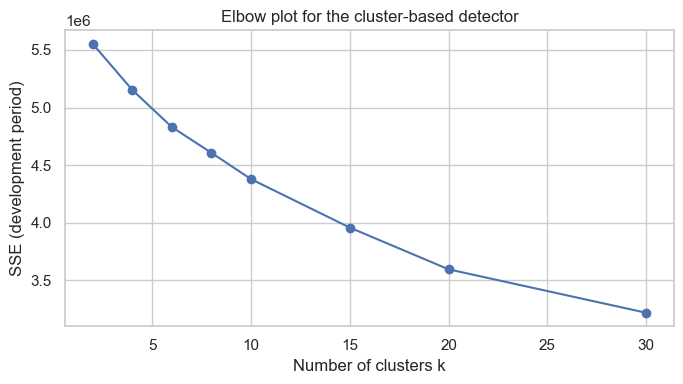

{2: np.float64(5.553), 4: np.float64(5.153), 6: np.float64(4.83), 8: np.float64(4.607), 10: np.float64(4.378), 15: np.float64(3.957), 20: np.float64(3.594), 30: np.float64(3.216)} (SSE in millions)


In [58]:
ks = [2, 4, 6, 8, 10, 15, 20, 30]
sse = [KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(X_dev).inertia_ for k in ks]
plt.figure(figsize=(7, 4)); plt.plot(ks, sse, "bo-"); plt.xlabel("Number of clusters k"); plt.ylabel("SSE (development period)")
plt.title("Elbow plot for the cluster-based detector")
plt.tight_layout()
plt.show()
print(dict(zip(ks, np.round(np.array(sse) / 1e6, 3))), "(SSE in millions)")

**Interpretation.** 
-   SSE falls smoothly from 5.55 million (k = 2) to 3.22 million (k = 30), with **no sharp elbow**. The decrease slows gradually through k ≈ 6–10. That is typical of large, continuous data without well-separated groups. We fix **k = 10**, at the end of the region where the curve bends, **before** looking at any labels

In [59]:
K_CB = 10
km = KMeans(n_clusters=K_CB, n_init=5, random_state=SEED).fit(X_dev)
km_score = km.transform(X_ev).min(axis=1)                  # distance to the nearest centroid
results.append(evaluate_ranking(km_score, f"Cluster-based: k-means distance (k={K_CB})")); scores_store["Cluster-based"] = km_score
print("Development cluster sizes:", np.bincount(km.labels_))
pd.DataFrame(results).set_index("detector")

Development cluster sizes: [55210 12610 48926 21207  3589   217 18546 25006  1353 11945]


,PR-AUC,ROC-AUC,precision@100,recall@100,precision@500,recall@500,precision@1000,recall@1000,€ fraud caught in top 1000
detector,,,,,,,,,
Random ranking (reference),0.0021,0.5716,0.0200,0.0187,0.0060,0.0280,0.0040,0.0374,0.0088
Statistical baseline: max |Z|,0.0353,0.9383,0.0000,0.0000,0.0500,0.2336,0.0490,0.4579,0.1773
Statistical baseline: Mahalanobis,0.0356,0.9457,0.0000,0.0000,0.0380,0.1776,0.0570,0.5327,0.3066
Cluster-based: k-means distance (k=10),0.0449,0.9505,0.0000,0.0000,0.0520,0.2430,0.0610,0.5701,0.3738


**Interpretation**
- The cluster-based detector reaches **PR-AUC 0.045 and ROC-AUC 0.951**, slightly better than both statistical baselines on every ranking measure. Its top 1,000 transactions catch **57% of frauds** (vs 53% for Mahalanobis) and **37% of fraudulent euros** (vs 31%).
- **Why it helps:** the cluster sizes (from 217 to 55,210 transactions) show that "normal" behaviour consists of **several groups** of quite different sizes. Measuring distance to the *nearest* group fits that better than distance to one overall centre.
- **Limitation:** like the baselines, it puts **no frauds in its top 100**. The most distant points from every cluster are rare but genuine transactions.


## Classification-based approach

### One-Class Support Vector Machine (trained only on development data, no labels)
**Why a classification-based detector?** Classification-based anomaly detection learns a **decision boundary around the normal class**, and anything outside it is an anomaly . With labels withheld and fraud extremely rare, the **one-class** version fits best: it is trained on development transactions, assumed to be almost all genuine (fraud is about 0.17%), and learns a flexible, non-linear boundary of "normal" using an RBF kernel. That is the same idea as the autoencoder, which is trained only on normal samples.

**Settings (fixed before evaluation):**
- `nu = 0.01`: the maximum share of training transactions allowed outside the boundary, slightly above the known fraud rate to allow for other unusual but genuine transactions.
- `gamma = "scale"`: the scikit-learn default kernel width.
- A **random sample of 5,000** development transactions. The SVM's training cost grows roughly with the square of the number of rows, so the full 200,000 is impractical.

In [60]:
rng = np.random.default_rng(SEED)
train_idx = rng.choice(len(X_dev), 5000, replace=False)
ocsvm = OneClassSVM(kernel="rbf", nu=0.01, gamma="scale").fit(X_dev[train_idx])
oc_score = -ocsvm.decision_function(X_ev)                   # higher = further outside the 'normal' boundary
results.append(evaluate_ranking(oc_score, "Classification-based: One-Class SVM")); scores_store["Classification-based"] = oc_score
print("Support vectors:", len(ocsvm.support_))
pd.DataFrame(results).set_index("detector")

Support vectors: 256


,PR-AUC,ROC-AUC,precision@100,recall@100,precision@500,recall@500,precision@1000,recall@1000,€ fraud caught in top 1000
detector,,,,,,,,,
Random ranking (reference),0.0021,0.5716,0.0200,0.0187,0.0060,0.0280,0.0040,0.0374,0.0088
Statistical baseline: max |Z|,0.0353,0.9383,0.0000,0.0000,0.0500,0.2336,0.0490,0.4579,0.1773
Statistical baseline: Mahalanobis,0.0356,0.9457,0.0000,0.0000,0.0380,0.1776,0.0570,0.5327,0.3066
Cluster-based: k-means distance (k=10),0.0449,0.9505,0.0000,0.0000,0.0520,0.2430,0.0610,0.5701,0.3738
Classification-based: One-Class SVM,0.0403,0.9354,0.0000,0.0000,0.0560,0.2617,0.0550,0.5140,0.6402


**Interpretation**
- The One-Class SVM reaches **PR-AUC 0.040 and ROC-AUC 0.935**. That is better than the statistical baselines in PR-AUC, slightly below the cluster-based detector, and comparable overall.
- **Its strength is high-value fraud:** its top 1,000 transactions contain **64% of all fraudulent euros**, far more than the cluster-based detector (37%) and Mahalanobis (31%). Its flexible non-linear boundary appears to isolate unusual, *larger* frauds well.
- **Its weakness is cost and instability.** It can only be trained on a sample (5,000 of 198,609 transactions), and its results shown depend strongly on which sample is drawn.

### Reference only: a supervised classifier that *uses* the labels
The task withholds the labels, so this model is **not** one of our detectors. It answers a useful question: *how much better could we do if past fraud labels were available?* A regularised logistic regression is trained on the **development-period labels** and scored on the evaluation period.

In [61]:
sup = LogisticRegression(C=0.1, max_iter=2000).fit(X_dev, dev["Class"])
sup_score = sup.predict_proba(X_ev)[:, 1]
results.append(evaluate_ranking(sup_score, "REFERENCE: supervised logistic regression (uses labels)")); scores_store["Supervised reference"] = sup_score
pd.DataFrame(results).set_index("detector")

,PR-AUC,ROC-AUC,precision@100,recall@100,precision@500,recall@500,precision@1000,recall@1000,€ fraud caught in top 1000
detector,,,,,,,,,
Random ranking (reference),0.0021,0.5716,0.0200,0.0187,0.0060,0.0280,0.0040,0.0374,0.0088
Statistical baseline: max |Z|,0.0353,0.9383,0.0000,0.0000,0.0500,0.2336,0.0490,0.4579,0.1773
Statistical baseline: Mahalanobis,0.0356,0.9457,0.0000,0.0000,0.0380,0.1776,0.0570,0.5327,0.3066
Cluster-based: k-means distance (k=10),0.0449,0.9505,0.0000,0.0000,0.0520,0.2430,0.0610,0.5701,0.3738
Classification-based: One-Class SVM,0.0403,0.9354,0.0000,0.0000,0.0560,0.2617,0.0550,0.5140,0.6402
REFERENCE: supervised logistic regression (uses labels),0.6997,0.9748,0.7200,0.6729,0.1840,0.8598,0.0920,0.8598,0.8293



## Comparing the detectors

,PR-AUC,ROC-AUC,precision@100,recall@100,precision@500,recall@500,precision@1000,recall@1000,€ fraud caught in top 1000
detector,,,,,,,,,
Random ranking (reference),0.0021,0.5716,0.0200,0.0187,0.0060,0.0280,0.0040,0.0374,0.0088
Statistical baseline: max |Z|,0.0353,0.9383,0.0000,0.0000,0.0500,0.2336,0.0490,0.4579,0.1773
Statistical baseline: Mahalanobis,0.0356,0.9457,0.0000,0.0000,0.0380,0.1776,0.0570,0.5327,0.3066
Cluster-based: k-means distance (k=10),0.0449,0.9505,0.0000,0.0000,0.0520,0.2430,0.0610,0.5701,0.3738
Classification-based: One-Class SVM,0.0403,0.9354,0.0000,0.0000,0.0560,0.2617,0.0550,0.5140,0.6402
REFERENCE: supervised logistic regression (uses labels),0.6997,0.9748,0.7200,0.6729,0.1840,0.8598,0.0920,0.8598,0.8293


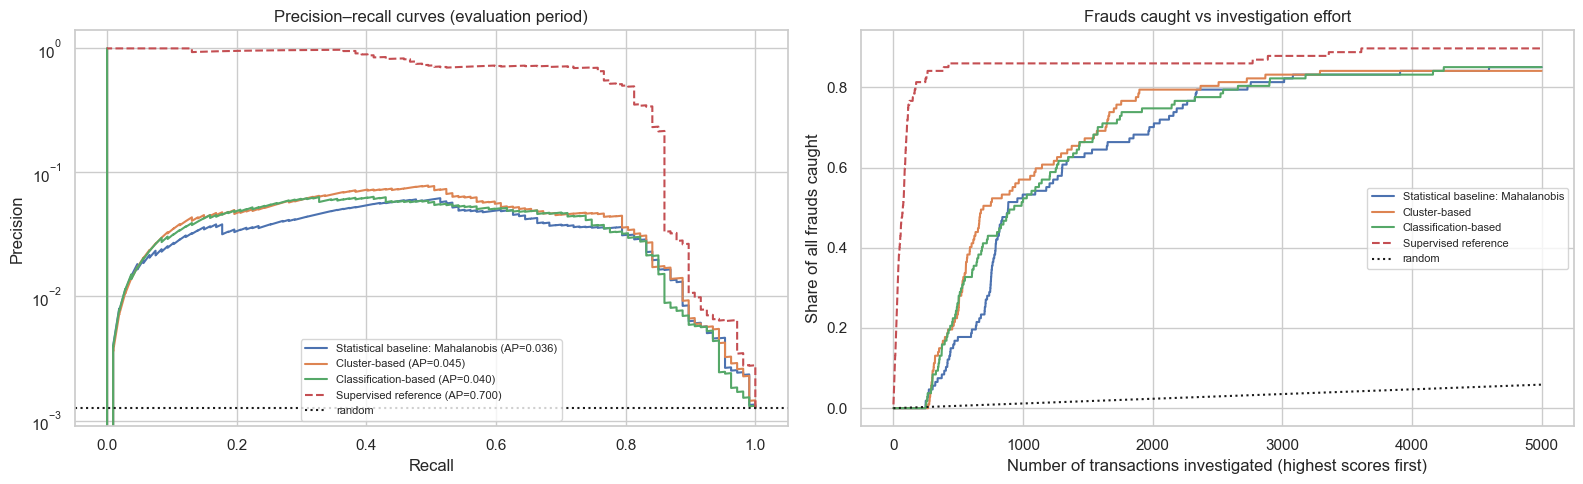

In [62]:
res_tbl = pd.DataFrame(results).set_index("detector")
display(res_tbl.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
show = ["Statistical baseline: Mahalanobis", "Cluster-based", "Classification-based", "Supervised reference"]
for name in show:
    s = scores_store[name]; p, r, _ = precision_recall_curve(y_ev, s)
    axes[0].plot(r, p, label=f"{name} (AP={average_precision_score(y_ev, s):.3f})", ls="--" if "Supervised" in name else "-")
    order = np.argsort(-s); caught = np.cumsum(y_ev[order]) / y_ev.sum()
    axes[1].plot(np.arange(1, 5001), caught[:5000], label=name, ls="--" if "Supervised" in name else "-")
axes[0].axhline(y_ev.mean(), color="k", ls=":", label="random"); axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision–recall curves (evaluation period)", yscale="log")
axes[1].plot([0, 5000], [0, 5000 / len(y_ev)], "k:", label="random"); axes[1].set(xlabel="Number of transactions investigated (highest scores first)", ylabel="Share of all frauds caught", title="Frauds caught vs investigation effort")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**How certain are the differences?** 
-   The evaluation period contains only about a hundred frauds, so we compute **bootstrap 95% confidence intervals** for PR-AUC (1,000 resamples).

In [63]:
rng = np.random.default_rng(SEED); boot = {n: [] for n in show}
for _ in range(1000):
    idx = rng.integers(0, len(y_ev), len(y_ev))
    for n in show:
        boot[n].append(average_precision_score(y_ev[idx], scores_store[n][idx]))
ci = pd.DataFrame({n: {"PR-AUC": average_precision_score(y_ev, scores_store[n]), "95% CI low": np.percentile(v, 2.5), "95% CI high": np.percentile(v, 97.5)} for n, v in boot.items()}).T
diff_cb_oc = np.array(boot["Classification-based"]) - np.array(boot["Cluster-based"])
print(f"PR-AUC difference (classification-based − cluster-based): {diff_cb_oc.mean():.4f}, 95% CI [{np.percentile(diff_cb_oc, 2.5):.4f}, {np.percentile(diff_cb_oc, 97.5):.4f}]")
ci

PR-AUC difference (classification-based − cluster-based): -0.0046, 95% CI [-0.0104, 0.0009]


,PR-AUC,95% CI low,95% CI high
Statistical baseline: Mahalanobis,0.0356,0.0272,0.0469
Cluster-based,0.0449,0.0339,0.0590
Classification-based,0.0403,0.0301,0.0532
Supervised reference,0.6997,0.6065,0.7802


**Do the detectors flag the same transactions?**

In [64]:
top_sets = {n: set(np.argsort(-scores_store[n])[:1000]) for n in show}
overlap = pd.DataFrame({a: {b: len(top_sets[a] & top_sets[b]) / 1000 for b in show} for a in show})
print("Share of the top-1000 transactions shared by each pair of detectors:")
overlap.round(2)

Share of the top-1000 transactions shared by each pair of detectors:


,Statistical baseline: Mahalanobis,Cluster-based,Classification-based,Supervised reference
Statistical baseline: Mahalanobis,1.0000,0.9000,0.7200,0.2000
Cluster-based,0.9000,1.0000,0.7200,0.1900
Classification-based,0.7200,0.7200,1.0000,0.2100
Supervised reference,0.2000,0.1900,0.2100,1.0000


**Comparison**

| Detector | PR-AUC (95% CI) | ROC-AUC | Frauds caught in top 1,000 | € caught in top 1,000 | Strengths | Weaknesses |
|---|---|---|---|---|---|---|
| Statistical baseline (Mahalanobis) | 0.036 (0.027–0.047) | 0.946 | 57 of 107 (53%) | 31% | Simple, transparent, no tuning | Assumes one Gaussian "normal" group; heavy tails violate it |
| **Cluster-based (k-means distance)** | **0.045** (0.034–0.059) | **0.951** | **61 (57%)** | 37% | Models several types of normal behaviour; fast on all 200,000 transactions; scores new data instantly | Depends on k; distance treats all directions equally |
| **Classification-based (One-Class SVM)** | 0.040 (0.030–0.053) | 0.935 | 55 (51%) | **64%** | Flexible non-linear boundary; best at catching *high-value* fraud | Must be trained on a sample; sensitive to which sample; slower |
| *Reference: supervised (uses labels)* | *0.700* (0.607–0.780) | *0.975* | *92 (86%)* | *83%* | Learns what fraud looks like | Needs confirmed fraud labels; may miss *new* fraud patterns |

**Key points**
1. **Both approaches work, and neither is clearly better.** The cluster-based detector has slightly higher PR-AUC and ROC-AUC, but the difference from the One-Class SVM is **not statistically significant** (bootstrap 95% CI for the difference: −0.010 to +0.001). The choice should therefore rest on practical considerations: the cluster-based detector is **faster, simpler and more stable**, while the One-Class SVM catches **more of the money** lost to fraud.
2. **Both beat the statistical baseline modestly**, consistent with "normal" behaviour being more complex than one Gaussian cloud.
3. **The detectors largely agree.** The cluster-based and Mahalanobis top-1,000 lists share 90% of transactions, and the One-Class SVM shares 72% with each. They all find the same kind of "unusual". The supervised reference shares only about 20% with them: **what is unusual and what is fraudulent overlap only partly**.
4. **Labels change everything.** The supervised reference has about 15 times the PR-AUC and puts 72 frauds in its top 100, where every unsupervised detector has none. Unsupervised anomaly detection is useful for spotting **new or unknown** fraud patterns, but it cannot match a model that knows what fraud looks like.


## Sensitivity analysis
How much do the conclusions depend on choices made without labels? We vary one choice at a time and report PR-AUC and recall@1000 on the evaluation period.

In [65]:
sens = []
for k in [5, 10, 20, 50]:
    s = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(X_dev).transform(X_ev).min(axis=1)
    r = evaluate_ranking(s, f"k-means k={k}"); sens.append({"approach": "Cluster-based", "setting": f"k = {k}", "PR-AUC": r["PR-AUC"], "recall@1000": r["recall@1000"]})
for n_train in [2000, 5000, 10000]:
    for nu in [0.005, 0.01, 0.05]:
        idx = np.random.default_rng(SEED).choice(len(X_dev), n_train, replace=False)
        s = -OneClassSVM(kernel="rbf", nu=nu, gamma="scale").fit(X_dev[idx]).decision_function(X_ev)
        r = evaluate_ranking(s, ""); sens.append({"approach": "Classification-based", "setting": f"sample {n_train:,}, nu = {nu}", "PR-AUC": r["PR-AUC"], "recall@1000": r["recall@1000"]})
for seed in [1, 2, 3]:
    idx = np.random.default_rng(seed).choice(len(X_dev), 5000, replace=False)
    s = -OneClassSVM(kernel="rbf", nu=0.01, gamma="scale").fit(X_dev[idx]).decision_function(X_ev)
    r = evaluate_ranking(s, ""); sens.append({"approach": "Classification-based", "setting": f"different random sample (seed {seed})", "PR-AUC": r["PR-AUC"], "recall@1000": r["recall@1000"]})
# features: without amount / with time-of-day context
for label, cols in [("without log_amount", V_COLS), ("with hour-of-day (sin/cos)", FEATURES + ["hour_sin", "hour_cos"])]:
    d2, e2 = dev.copy(), ev.copy()
    for d in (d2, e2):
        h = (d["Time"] % 86400) / 3600; d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    sc2 = StandardScaler().fit(d2[cols]); A, B = sc2.transform(d2[cols]), sc2.transform(e2[cols])
    s_km = KMeans(n_clusters=K_CB, n_init=3, random_state=SEED).fit(A).transform(B).min(axis=1)
    s_oc = -OneClassSVM(kernel="rbf", nu=0.01, gamma="scale").fit(A[train_idx]).decision_function(B)
    for ap, s in [("Cluster-based", s_km), ("Classification-based", s_oc)]:
        r = evaluate_ranking(s, ""); sens.append({"approach": ap, "setting": label, "PR-AUC": r["PR-AUC"], "recall@1000": r["recall@1000"]})
sens_tbl = pd.DataFrame(sens)
sens_tbl.round(4)

,approach,setting,PR-AUC,recall@1000
0,Cluster-based,k = 5,0.0398,0.5421
1,Cluster-based,k = 10,0.0449,0.5701
2,Cluster-based,k = 20,0.0604,0.6355
3,Cluster-based,k = 50,0.0909,0.7664
4,Classification-based,"sample 2,000, nu = 0.005",0.0780,0.7570
5,Classification-based,"sample 2,000, nu = 0.01",0.0781,0.7570
6,Classification-based,"sample 2,000, nu = 0.05",0.0778,0.7570
7,Classification-based,"sample 5,000, nu = 0.005",0.0403,0.5140
8,Classification-based,"sample 5,000, nu = 0.01",0.0403,0.5140
9,Classification-based,"sample 5,000, nu = 0.05",0.0473,0.6168


**Interpretation**
1. **Cluster-based: more clusters help here.** PR-AUC rises from 0.040 (k = 5) to 0.045 (k = 10), 0.060 (k = 20) and **0.091 (k = 50)**, with recall@1000 reaching 77%. Finer clusters describe normal behaviour more precisely, so frauds stand out more. **But we could not have chosen k = 50 without labels**: the elbow plot did not point to it. This is the central difficulty of unsupervised detection. A small labelled validation set, if available, would be valuable for tuning.
2. **Classification-based: very sensitive to the training sample.** With the same settings, different random samples of 5,000 give PR-AUC from **0.040 to 0.060**, and a sample of 2,000 gives **0.078**. `nu` matters less (0.005 and 0.01 give identical results). The One-Class SVM's results are therefore **less stable** than the cluster-based detector's: one sample is a fragile basis for a production system.
3. **Features:** removing `log_amount` or adding the hour of day changes PR-AUC only slightly (0.040–0.053). Our feature choices are not driving the conclusions.
4. **Overall:** across all settings, both approaches stay in the same range (PR-AUC 0.04–0.09, ROC-AUC about 0.93–0.95), always far above random (0.002) and always far below the supervised reference (0.70). The conclusion "both work, neither dominates, labels matter far more" is robust.


## Why an unusual transaction is not necessarily fraudulent

## Evidence: who are the *most* unusual transactions?

In [66]:
for name in ["Statistical baseline: Mahalanobis", "Cluster-based", "Classification-based"]:
    order = np.argsort(-scores_store[name])
    print(f"{name:35s} frauds among the 100 most unusual: {int(y_ev[order[:100]].sum()):3d} | among the top 1,000: {int(y_ev[order[:1000]].sum()):3d} of {int(y_ev.sum())}")

top100 = ev.loc[np.argsort(-scores_store["Cluster-based"])[:100]]
compare = pd.DataFrame({"100 most unusual (cluster-based)": top100["Amount"].describe(),
                        "all genuine (evaluation)": ev.loc[y_ev == 0, "Amount"].describe(),
                        "all frauds (evaluation)": ev.loc[y_ev == 1, "Amount"].describe()}).T
compare[["count", "mean", "50%", "max"]].round(2)

Statistical baseline: Mahalanobis   frauds among the 100 most unusual:   0 | among the top 1,000:  57 of 107
Cluster-based                       frauds among the 100 most unusual:   0 | among the top 1,000:  61 of 107
Classification-based                frauds among the 100 most unusual:   0 | among the top 1,000:  55 of 107


,count,mean,50%,max
100 most unusual (cluster-based),100.0000,"1,939.8000",445.7200,"25,691.1600"
all genuine (evaluation),"85,010.0000",85.1700,20.0000,"25,691.1600"
all frauds (evaluation),107.0000,136.1200,6.7400,"1,504.9300"


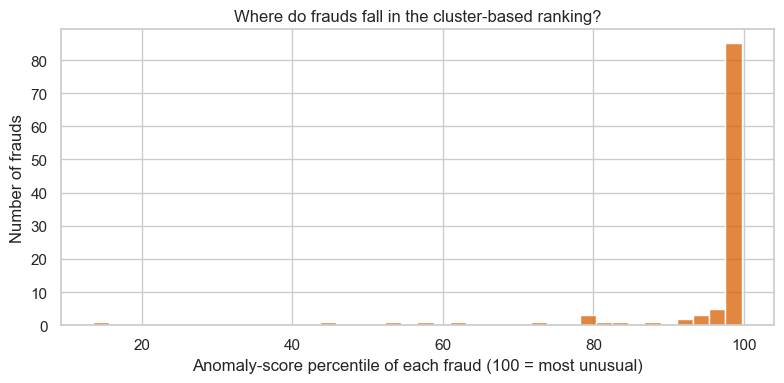

Frauds in the most unusual 1%: 53% | in the most unusual 5%: 84% | below the median (look normal): 2%


In [67]:
pct = pd.Series(scores_store["Cluster-based"]).rank(pct=True)
fraud_pct = pct[y_ev == 1]
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(fraud_pct * 100, bins=40, ax=ax, color="#d95f02")
ax.set(xlabel="Anomaly-score percentile of each fraud (100 = most unusual)", ylabel="Number of frauds", title="Where do frauds fall in the cluster-based ranking?")
plt.tight_layout()
plt.show()
print("Frauds in the most unusual 1%%: %.0f%% | in the most unusual 5%%: %.0f%% | below the median (look normal): %.0f%%"
      % (100 * (fraud_pct > 0.99).mean(), 100 * (fraud_pct > 0.95).mean(), 100 * (fraud_pct < 0.5).mean()))

### The base-rate effect

In [68]:
prevalence = y_ev.mean()
for sens_, fpr in [(0.90, 0.05), (0.90, 0.01), (0.99, 0.01)]:
    ppv = sens_ * prevalence / (sens_ * prevalence + fpr * (1 - prevalence))
    print(f"A detector that flags {sens_:.0%} of frauds and {fpr:.0%} of genuine transactions: only {ppv:.1%} of flagged transactions are fraud")

A detector that flags 90% of frauds and 5% of genuine transactions: only 2.2% of flagged transactions are fraud
A detector that flags 90% of frauds and 1% of genuine transactions: only 10.2% of flagged transactions are fraud
A detector that flags 99% of frauds and 1% of genuine transactions: only 11.1% of flagged transactions are fraud


### Why an unusual transaction is not necessarily fraudulent

**1. The data shows it directly.** For every detector, the **100 most unusual transactions contain zero frauds**. These are mostly **large, rare but legitimate payments**: their median amount is **€446** and their mean **€1,940** (up to €25,691), compared with a median of only **€6.74** for frauds and €20 for genuine transactions. Frauds are typically **small** (the largest in the evaluation period was €1,505). A big purchase is unusual, but most big purchases are genuine.

**2. Anomaly detectors measure rarity, not intent.** A detector scores a transaction as unusual because it is **far from typical behaviour**. Genuine reasons for that are common:
- a once-a-year purchase (furniture, flights, a car repair);
- spending abroad or in an unfamiliar currency;
- a new type of merchant, or a change in life circumstances (a new job, moving house);
- business or bulk purchases;
- data or system effects, such as €0 authorisation checks (1,825 in this data).

These are **contextual** situations . The same transaction may be normal for one cardholder and unusual for another, but the dataset has no cardholder ID to provide that context.

**3. Fraudsters try to look normal.** Many frauds are deliberately **small and ordinary-looking**, for example "testing" a stolen card with a small purchase. Even so, frauds are mostly *moderately* unusual rather than *extremely* unusual: **53%** fall in the most unusual 1% of scores and **84%** in the most unusual 5%, but almost none are at the very top. **2%** of frauds even score below the median and would never be investigated by an anomaly ranking.

**4. The base-rate effect.** Fraud is extremely rare (0.13% of evaluation transactions). Even a very good detector that flags **99% of frauds** and only **1% of genuine transactions** would find that **only about 11%** of its flags are fraud . With 85,000 genuine transactions, 1% is still about 850 false alarms against roughly 106 true frauds.

**5. Correlation with the label is not the definition of the label.** "Fraud" is a *legal and behavioural* fact (the cardholder did not authorise the payment), not a statistical one. Unusualness is evidence that raises suspicion, which is why the detector is used to **prioritise investigation**, not to decide guilt.

**Conclusion.** Unusual and fraudulent are **related but different**. Anomaly scores help focus attention, but a flagged transaction must be **verified**, for example by contacting the customer, before any action is taken.


## Conclusions, limitations and responsible use

### Conclusions

1. **Exploration, preparation and baseline (Task 1).** The data contains 284,807 anonymised transactions over two days with 0.17% fraud. 1,081 duplicates were removed, the amount was log-transformed, `Time` was excluded as a feature, and the data was split by time into development and evaluation periods. The **statistical baseline** (Mahalanobis distance) already ranks fraud far above chance (ROC-AUC 0.95, PR-AUC 0.036 vs 0.002 random).
2. **Cluster-based vs classification-based (Task 2).** The **cluster-based** detector (k-means distance, PR-AUC 0.045) and the **classification-based** One-Class SVM (PR-AUC 0.040) both beat the baseline modestly and are **statistically tied**. The cluster-based detector is faster, simpler and more stable; the One-Class SVM catches more fraudulent euros (64% vs 37% in the top 1,000) but depends strongly on its training sample. Using labels (supervised reference, PR-AUC 0.70) would be about 15 times better.
3. **Unusual ≠ fraudulent (Task 3).** The most extreme transactions are rare but genuine (no frauds in any detector's top 100). Fraud is mostly *moderately* unusual and small, and the base rate means most flags will be false alarms.
4. **Recommendation.** Deploy an anomaly score (the cluster-based detector is the simpler choice) to **prioritise** human review and to watch for **new** fraud patterns, alongside a supervised model trained on confirmed fraud cases. Never block cards or accuse customers on the anomaly score alone.

### Limitations
1. **Two days of data.** Fraud patterns change. A detector must be refitted and monitored over time.
2. **Anonymised features.** We cannot explain in business terms *why* a transaction scored high, which makes it harder for investigators to act on a flag.
3. **No cardholder ID.** We cannot detect *contextual* anomalies (unusual for this person) or *collective* ones (bursts of activity on one card), which are often the strongest fraud signals in practice.
4. **Imperfect labels.** Undetected fraud may be labelled genuine, so precision may be slightly under-estimated.
5. **Small number of frauds in the evaluation period** (about a hundred). The confidence intervals are wide, so small differences between detectors are not reliable.

### Responsible use
- Use the scores to **prioritise human review**, never to block cards or accuse customers automatically. Most flagged transactions are genuine (Step 10).
- Give customers a **fast, simple way to confirm** a flagged transaction, to limit inconvenience for those wrongly flagged.
- Monitor whether some customer groups are flagged much more often, for example frequent travellers or people whose habits change. Respect data-protection law (e.g. GDPR for this European data).
- Combine unsupervised detectors (which can spot *new* fraud patterns) with supervised models trained on confirmed fraud cases (which are far more precise for *known* patterns).